In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from torchvision import datasets
import torchvision

In [2]:
dataset= datasets.EuroSAT(root="data", download=True)

In [3]:
from pathlib import Path
data_path= Path("data/")
image_path= data_path/ "eurosat"

In [4]:
image_path

WindowsPath('data/eurosat')

In [5]:
import os

In [6]:
def check_data(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"dirnames:{len(dirnames)} file_count:{len(filenames)} in {dirpath}")

In [7]:
check_data(image_path)

dirnames:1 file_count:1 in data\eurosat
dirnames:10 file_count:0 in data\eurosat\2750
dirnames:1 file_count:3000 in data\eurosat\2750\AnnualCrop
dirnames:0 file_count:2 in data\eurosat\2750\AnnualCrop\.ipynb_checkpoints
dirnames:0 file_count:3000 in data\eurosat\2750\Forest
dirnames:0 file_count:3000 in data\eurosat\2750\HerbaceousVegetation
dirnames:0 file_count:2500 in data\eurosat\2750\Highway
dirnames:0 file_count:2500 in data\eurosat\2750\Industrial
dirnames:0 file_count:2000 in data\eurosat\2750\Pasture
dirnames:0 file_count:2500 in data\eurosat\2750\PermanentCrop
dirnames:0 file_count:3000 in data\eurosat\2750\Residential
dirnames:0 file_count:2500 in data\eurosat\2750\River
dirnames:0 file_count:3000 in data\eurosat\2750\SeaLake


In [8]:
from torchvision import transforms

In [9]:
train_transform= transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform= transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

## 🤖 AI notu: Train / Test bölme (klasörlere ayırma)

EuroSAT tek klasör halinde geliyor (`data/eurosat/2750`). Aşağıdaki hücre resimleri **her sınıfı kendi içinde %80 train / %20 test** olacak şekilde
`data/eurosat_split/train` ve `data/eurosat_split/test` klasörlerine kopyalar. Sonra Desert101'deki gibi `ImageFolder` ile yüklenir;
böylece train'e augmentation, test'e augmentation'sız transform kolayca verilir.

- Bölme hücresi **sadece bir kere** çalıştırılır; klasörler zaten varsa kendini atlar.
- Sadece `*.jpg` dosyaları alındığı için `.ipynb_checkpoints` klasörleri karışmaz.
- `data/` `.gitignore`'da olduğu için bu klasörler GitHub'a gitmez.

In [10]:
# 🤖 AI notu: Resimleri train/test klasörlerine ayırma (tek seferlik)
import random, shutil

src_dir = image_path / "2750"            # orijinal resimler
split_dir = data_path / "eurosat_split"  # yeni train/test klasörleri

if (split_dir / "train").exists():
    print("Bölme zaten yapılmış, atlanıyor:", split_dir)
else:
    random.seed(42)
    for class_dir in sorted(src_dir.iterdir()):
        if not class_dir.is_dir() or class_dir.name.startswith("."):
            continue
        images = sorted(class_dir.glob("*.jpg"))
        random.shuffle(images)
        n_train = int(0.8 * len(images))     # her sınıfın %80'i train'e

        for i, img in enumerate(images):
            split = "train" if i < n_train else "test"
            out = split_dir / split / class_dir.name
            out.mkdir(parents=True, exist_ok=True)
            shutil.copy(img, out / img.name)
    print("Bölme tamamlandı:", split_dir)

check_data(split_dir)

Bölme zaten yapılmış, atlanıyor: data\eurosat_split
dirnames:2 file_count:0 in data\eurosat_split
dirnames:10 file_count:0 in data\eurosat_split\test
dirnames:0 file_count:600 in data\eurosat_split\test\AnnualCrop
dirnames:0 file_count:600 in data\eurosat_split\test\Forest
dirnames:0 file_count:600 in data\eurosat_split\test\HerbaceousVegetation
dirnames:0 file_count:500 in data\eurosat_split\test\Highway
dirnames:0 file_count:500 in data\eurosat_split\test\Industrial
dirnames:0 file_count:400 in data\eurosat_split\test\Pasture
dirnames:0 file_count:500 in data\eurosat_split\test\PermanentCrop
dirnames:0 file_count:600 in data\eurosat_split\test\Residential
dirnames:0 file_count:500 in data\eurosat_split\test\River
dirnames:0 file_count:600 in data\eurosat_split\test\SeaLake
dirnames:10 file_count:0 in data\eurosat_split\train
dirnames:0 file_count:2400 in data\eurosat_split\train\AnnualCrop
dirnames:0 file_count:2400 in data\eurosat_split\train\Forest
dirnames:0 file_count:2400 in dat

In [11]:
train_data= datasets.ImageFolder(root= split_dir / "train", transform=train_transform)
test_data= datasets.ImageFolder(root= split_dir / "test", transform=test_transform)

print(f"train: {len(train_data)}")
print(f"test: {len(test_data)}")
print(train_data.classes)

train: 21600
test: 5400
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [12]:
from torch.utils.data import DataLoader

In [13]:
BATCH_SIZE=32
train_dataloader= DataLoader(dataset=train_data,
                            batch_size=BATCH_SIZE,
                            shuffle=True)

test_dataloader= DataLoader(dataset=test_data,
                           batch_size=BATCH_SIZE,
                           shuffle=False)

In [14]:
class_name= train_data.classes
class_name

['AnnualCrop',
 'Forest',
 'HerbaceousVegetation',
 'Highway',
 'Industrial',
 'Pasture',
 'PermanentCrop',
 'Residential',
 'River',
 'SeaLake']

In [15]:
class EuroSATClassifier(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()

        self.conv_block1= nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1
                    ),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1
                     ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                        stride=2)
        )

        self.conv_block2= nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      padding=1,
                      stride=1
                     ),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1
                     ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                        stride=2)
        )

        self.classifier= nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units * 16 * 16,
                     out_features=output_shape)
        )

    def forward(self, x):
        return self.classifier(self.conv_block2(self.conv_block1(x)))

In [16]:
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu" 
model_0= EuroSATClassifier(
        input_shape=3,
        hidden_units=32,
        output_shape=len(class_name)
).to(device)
device

'cuda'

In [17]:
from torchinfo import summary
summary(model_0, [1,3,64,64])

Layer (type:depth-idx)                   Output Shape              Param #
EuroSATClassifier                        [1, 10]                   --
├─Sequential: 1-1                        [1, 32, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 32, 64, 64]           896
│    └─ReLU: 2-2                         [1, 32, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 32, 64, 64]           9,248
│    └─ReLU: 2-4                         [1, 32, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 32, 32, 32]           --
├─Sequential: 1-2                        [1, 32, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 32, 32, 32]           9,248
│    └─ReLU: 2-7                         [1, 32, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 32, 32, 32]           9,248
│    └─ReLU: 2-9                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 32, 16, 16]           --
├─Seq

In [18]:
def train_step(model, data_loader, loss_fn, optimizer):
    model.train()

    train_loss=0
    train_acc=0

    for batch, (X, y) in enumerate(data_loader):
        X, y= X.to(device), y.to(device)
        y_pred= model(X)
        loss= loss_fn(y_pred, y)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_pred_class= torch.argmax(y_pred, dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y)

    return train_loss / len(data_loader), train_acc / len (data_loader)

In [19]:
def test_step(model, data_laoder, loss_fn):
    model.eval()

    test_loss=0
    test_acc=0

    with torch.inference_mode():
        for batch, (X, y) in enumerate(data_laoder):
            X, y= X.to(device), y.to(device)
            test_pred_logits= model(X)
            loss= loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            test_pred_label= torch.argmax(test_pred_logits, dim=1)
            test_acc += (test_pred_label == y).sum().item() / len(y) 

    return test_loss / len(data_laoder), test_acc / len(data_laoder)

In [20]:
from torch.optim import Adam

In [21]:
def train(model, train_data_loader, test_data_loader, optimizer, loss_fn, epochs):
    
    result={
        "train_loss" : [],
        "train_acc" : [],
        "test_loss" : [],
        "test_acc" : []
    }

    for epoch in range(epochs):
        train_loss, train_acc= train_step(
                                model=model,
                                data_loader=train_data_loader,
                                loss_fn=loss_fn,
                                optimizer=optimizer
                              )
        test_loss, test_acc= test_step(
                                model=model,
                                data_laoder=test_data_loader,
                                loss_fn=loss_fn
                            )
        print(f"Epoch:{epoch}, Train loss:{train_loss}, Train acc:{train_acc}, Test loss:{test_loss}, Test acc:{test_acc}")

        result["train_loss"].append(train_loss)
        result["train_acc"].append(train_acc)
        result["test_loss"].append(test_loss)
        result["test_acc"].append(test_acc)
    return result

In [22]:
loss_fn=nn.CrossEntropyLoss()
optimizer=Adam(params=model_0.parameters(), lr=0.001)
model_0_result= train(model=model_0, train_data_loader=train_dataloader, test_data_loader=test_dataloader, optimizer=optimizer, loss_fn=loss_fn, epochs=10)

Epoch:0, Train loss:1.1093153246243794, Train acc:0.5875925925925926, Test loss:0.7653742861994625, Test acc:0.7260848126232742
Epoch:1, Train loss:0.6712703220049541, Train acc:0.7613888888888889, Test loss:0.5988348979701305, Test acc:0.7896326429980276
Epoch:2, Train loss:0.5472669212906449, Train acc:0.8076388888888889, Test loss:0.5232873614546816, Test acc:0.820697731755424
Epoch:3, Train loss:0.4821178162318689, Train acc:0.8316203703703704, Test loss:0.4308847041701424, Test acc:0.8521942800788955
Epoch:4, Train loss:0.41562581517078256, Train acc:0.86, Test loss:0.40816834969060306, Test acc:0.8673570019723866
Epoch:5, Train loss:0.3844131250403546, Train acc:0.8691666666666666, Test loss:0.349157120608146, Test acc:0.873828895463511
Epoch:6, Train loss:0.353848049480606, Train acc:0.8790277777777777, Test loss:0.3176903742360028, Test acc:0.8950320512820512
Epoch:7, Train loss:0.3378125697043207, Train acc:0.8842129629629629, Test loss:0.3006927658192064, Test acc:0.903106508

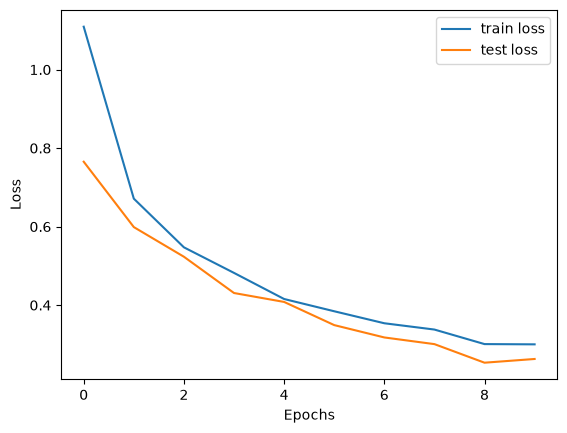

In [23]:
plt.plot(model_0_result["train_loss"], label="train loss" )
plt.plot(model_0_result["test_loss"], label="test loss")
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

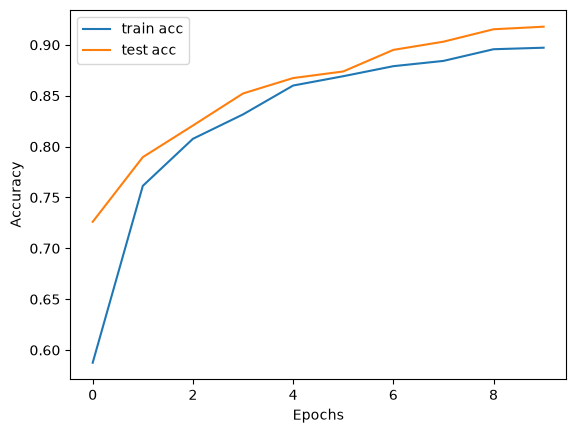

In [24]:
plt.plot(model_0_result["train_acc"], label="train acc")
plt.plot(model_0_result["test_acc"], label="test acc")
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

In [25]:
model_path=Path("models")
model_path.mkdir(exist_ok=True)

torch.save(model_0.state_dict(), model_path / "eurosat_model_0.pth")

In [26]:
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )

class EuroSATCNNv2(nn.Module):
    def __init__(self, output_shape):
        super().__init__()

        self.features=nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128)
        )

        self.linear=nn.Sequential(
            nn.AdaptiveAvgPool2d(1), # Her özellik haritasını tek bir değere indirmek ve sabit boyutlu bir çıktı elde etmektir.
            nn.Flatten(),
            nn.Dropout(0.3), #Modelin belirli nöronlara aşırı bağımlı hale gelmesini önlemeye yardımcı olmaktır.
            nn.Linear(128, output_shape ) #avarage pooling ile 128 x 1 x 1 yaptığımız için direkt 128
        )

    def forward(self, x):
        return self.linear(self.features(x))

In [27]:
torch.manual_seed(42)
model_1= EuroSATCNNv2(output_shape=len(class_name)).to(device)
summary(model_1, [1, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
EuroSATCNNv2                             [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 8, 8]            --
│    └─Sequential: 2-1                   [1, 32, 32, 32]           --
│    │    └─Conv2d: 3-1                  [1, 32, 64, 64]           896
│    │    └─BatchNorm2d: 3-2             [1, 32, 64, 64]           64
│    │    └─ReLU: 3-3                    [1, 32, 64, 64]           --
│    │    └─Conv2d: 3-4                  [1, 32, 64, 64]           9,248
│    │    └─BatchNorm2d: 3-5             [1, 32, 64, 64]           64
│    │    └─ReLU: 3-6                    [1, 32, 64, 64]           --
│    │    └─MaxPool2d: 3-7               [1, 32, 32, 32]           --
│    └─Sequential: 2-2                   [1, 64, 16, 16]           --
│    │    └─Conv2d: 3-8                  [1, 64, 32, 32]           18,496
│    │    └─BatchNorm2d: 3-9             [1, 64, 32, 32]           128
│    │

In [28]:
loss_fn=nn.CrossEntropyLoss()
optimizer= Adam(params=model_1.parameters(), lr=0.001)
model_1_result= train(model=model_1,
      train_data_loader=train_dataloader,
      test_data_loader=test_dataloader,
      optimizer=optimizer,
      loss_fn=loss_fn,
      epochs=10
    )

Epoch:0, Train loss:0.9482868476267214, Train acc:0.6679166666666667, Test loss:0.5759775104695524, Test acc:0.8025764299802761
Epoch:1, Train loss:0.6556699644415467, Train acc:0.7756944444444445, Test loss:0.5120195306440782, Test acc:0.8232248520710059
Epoch:2, Train loss:0.523492016394933, Train acc:0.8231481481481482, Test loss:0.4225377537821249, Test acc:0.8514546351084813
Epoch:3, Train loss:0.4621716246781526, Train acc:0.8452777777777778, Test loss:0.2841899089526231, Test acc:0.8952785996055227
Epoch:4, Train loss:0.4168152462221958, Train acc:0.8614814814814815, Test loss:0.3581264726046098, Test acc:0.877896942800789
Epoch:5, Train loss:0.35653744099316775, Train acc:0.8786574074074074, Test loss:0.27571539109305493, Test acc:0.9086538461538461
Epoch:6, Train loss:0.3365962758881074, Train acc:0.8856018518518518, Test loss:0.20457273232612824, Test acc:0.9278846153846154
Epoch:7, Train loss:0.30467162137782133, Train acc:0.9006481481481482, Test loss:0.17974791442286553, T

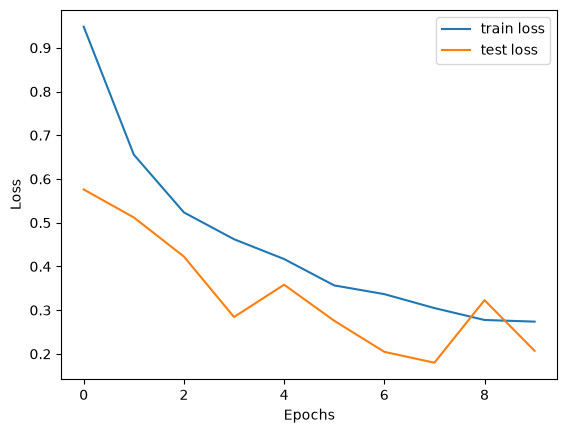

In [29]:
plt.plot(model_1_result["train_loss"], label="train loss")
plt.plot(model_1_result["test_loss"], label="test loss")
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

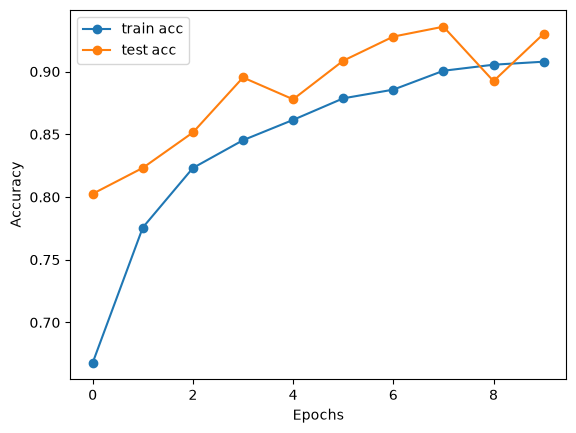

In [30]:
plt.plot(model_1_result["train_acc"], label="train acc", marker="o")
plt.plot(model_1_result["test_acc"], label="test acc", marker="o")
plt.legend()
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

In [31]:
torch.save(model_1.state_dict(), model_path / "eurosat_model_1.pth")

In [32]:
from torchvision import models

weights= models.ResNet18_Weights.DEFAULT
model_2= models.resnet18(weights=weights)
print(model_2.fc)

Linear(in_features=512, out_features=1000, bias=True)


In [33]:
model_2.fc= nn.Linear(model_2.fc.in_features, len(class_name))
model_2= model_2.to(device)

In [34]:
loss_fn= nn.CrossEntropyLoss()
optimizer= Adam(params=model_2.parameters(), lr=0.001)

model_2_result= train(model=model_2,
                      train_data_loader=train_dataloader,
                      test_data_loader=test_dataloader,
                      loss_fn=loss_fn,
                      optimizer=optimizer,
                      epochs=10
                     )

Epoch:0, Train loss:0.5997699357845165, Train acc:0.8100925925925926, Test loss:0.4234349131115751, Test acc:0.8679733727810651
Epoch:1, Train loss:0.37626997256168615, Train acc:0.8793518518518518, Test loss:0.330349547968979, Test acc:0.8850468441814595
Epoch:2, Train loss:0.31971468141785375, Train acc:0.8951388888888889, Test loss:0.5644051235316586, Test acc:0.8117603550295858
Epoch:3, Train loss:0.29467880799262614, Train acc:0.90875, Test loss:0.3091020184937939, Test acc:0.896388067061144
Epoch:4, Train loss:0.2583522734101172, Train acc:0.9167592592592593, Test loss:0.2900750889393264, Test acc:0.9063116370808678
Epoch:5, Train loss:0.25481400612327787, Train acc:0.9186111111111112, Test loss:0.1927507114238464, Test acc:0.9339866863905325
Epoch:6, Train loss:0.20175020394225915, Train acc:0.9316203703703704, Test loss:0.153249318358425, Test acc:0.9474852071005917
Epoch:7, Train loss:0.23628523287397843, Train acc:0.9227314814814814, Test loss:0.18950363892900685, Test acc:0.

In [35]:
model_2_v2=models.resnet18(weights=weights)
model_2_v2.fc= nn.Linear(model_2_v2.fc.in_features, len(class_name))
model_2_v2= model_2_v2.to(device)

In [36]:
loss_fn= nn.CrossEntropyLoss()
optimizer= Adam(params=model_2_v2.parameters(), lr=0.0001)
model_2_v2_result= train(model=model_2_v2,
                      train_data_loader=train_dataloader,
                      test_data_loader=test_dataloader,
                      loss_fn=loss_fn,
                      optimizer=optimizer,
                      epochs=5
                     )

Epoch:0, Train loss:0.44536319408703734, Train acc:0.8528703703703704, Test loss:0.15615135036717506, Test acc:0.9474852071005917
Epoch:1, Train loss:0.2276369161710695, Train acc:0.9225, Test loss:0.1341675449102103, Test acc:0.9548816568047337
Epoch:2, Train loss:0.18355187751352786, Train acc:0.9386111111111111, Test loss:0.11483403221365153, Test acc:0.9632026627218935
Epoch:3, Train loss:0.16132247443207437, Train acc:0.9445370370370371, Test loss:0.11226567108226808, Test acc:0.960552268244576
Epoch:4, Train loss:0.14595800729675426, Train acc:0.9516666666666667, Test loss:0.12239848728921641, Test acc:0.9570389546351086


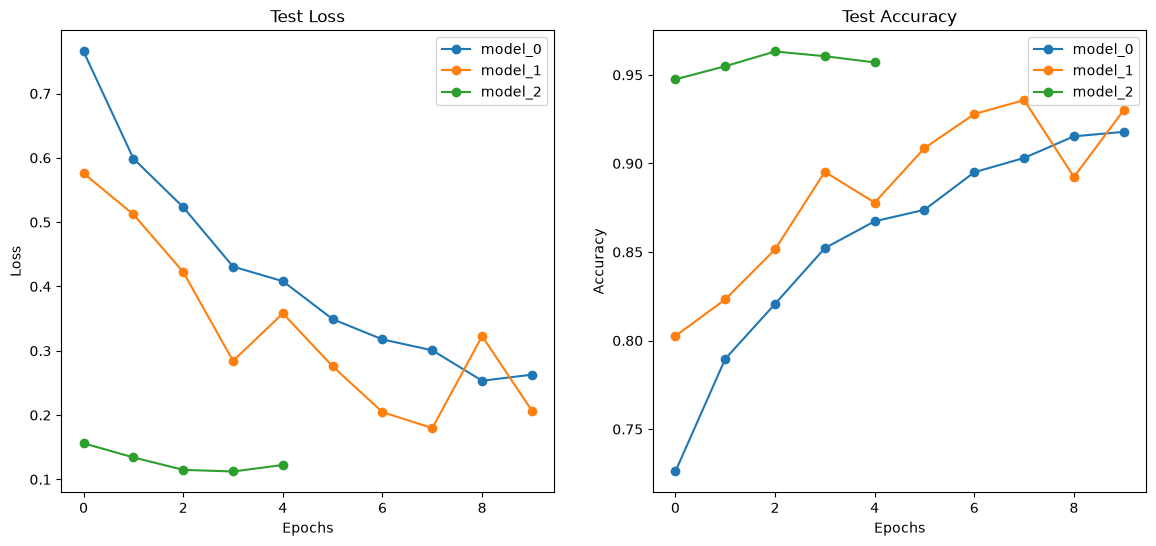

In [38]:
result= {
    "model_0" : model_0_result,
    "model_1" : model_1_result,
    "model_2" : model_2_v2_result
}

plt.figure(figsize=(14,6))
plt.subplot(1, 2, 1)
for name, r in result.items():
    plt.plot(r["test_loss"], label=name, marker="o")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
for name, r in result.items():
    plt.plot(r["test_acc"], label=name, marker="o")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [39]:
torch.save(model_2_v2.state_dict(), model_path / "eurosat_model_2.pth")

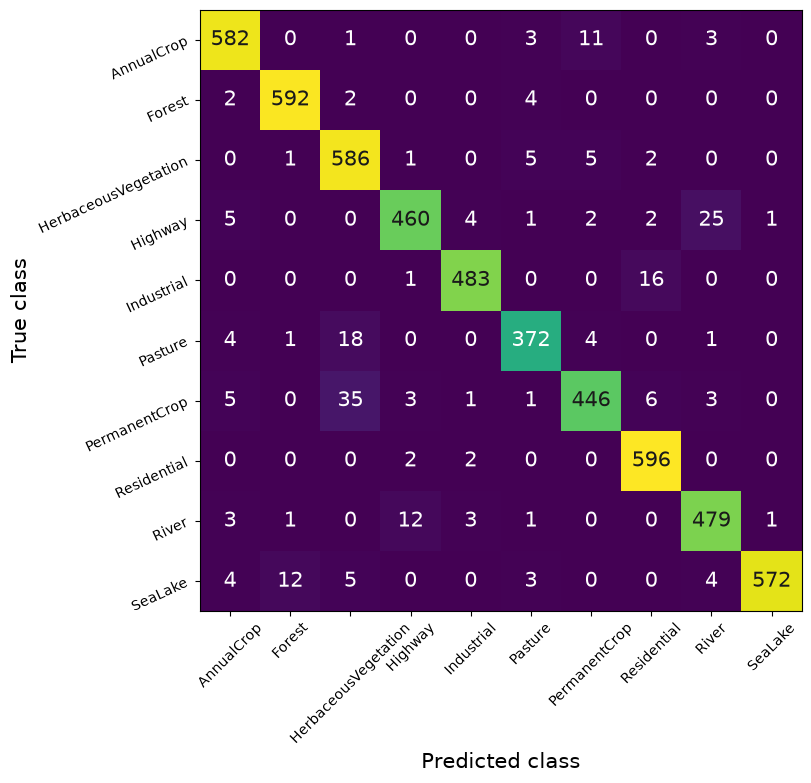

In [47]:
from torchmetrics.classification import MulticlassConfusionMatrix

cm= MulticlassConfusionMatrix(num_classes=len(class_name)).to(device)

model_2_v2.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X, y= X.to(device), y.to(device)
        preds= model_2_v2(X).argmax(dim=1)
        cm.update(preds, y)

fig, ax= cm.plot(labels=class_name)
fig.set_size_inches(8, 8)
plt.show()